# Identification des paramètres thermiques par fusion CNN-GRU + MLP

## Objectif de l'expérience

Cette expérience étudie une **architecture hybride combinant un CNN-GRU et un perceptron multicouche (MLP)** pour estimer les propriétés thermiques d'un bâtiment à partir de deux représentations complémentaires :

- **CNN-GRU :** extraction des caractéristiques temporelles à partir des signaux de température $T(t)$ et de sollicitation thermique $U(t)$.
- **MLP :** exploitation des caractéristiques statistiques extraites de ces mêmes signaux.

Les représentations apprises par les deux branches sont concaténées avant la prédiction des indicateurs thermiques.

La fonction de perte attribue une importance égale aux deux familles de cibles : **50 % aux coefficients de déperdition thermique et 50 % aux constantes de temps**.

L'objectif est d'évaluer si la combinaison des représentations temporelles et statistiques améliore l'estimation des paramètres thermiques par rapport aux modèles individuels.

## 1. Environnement d'exécution

Les fonctions de chargement des données, de définition des architectures, de calcul de la fonction de perte, d'entraînement et d'évaluation sont regroupées dans `src/coenergy/`.

Cette organisation modulaire permet de réutiliser les mêmes composants entre les expériences et d'assurer la reproductibilité des résultats.

In [29]:

from pathlib import Path
import sys
import shutil

import torch
from IPython.display import display


def find_source_directory():
    """Localise le dossier contenant les modules du projet."""

    # Recherche sur le PC
    current_directory = Path.cwd()

    for directory in [current_directory, *current_directory.parents]:
        source_directory = directory / "src"

        if (source_directory / "coenergy" / "loss.py").is_file():
            return source_directory

    # Recherche sur Kaggle
    kaggle_directory = Path("/kaggle/input")

    if kaggle_directory.exists():
        for file in kaggle_directory.rglob("loss.py"):
            if file.parent.name == "coenergy":
                return file.parent.parent

    raise FileNotFoundError("Modules coEnergy introuvables.")


source_directory = find_source_directory()
sys.path.insert(0, str(source_directory))

from coenergy.data import load_data, BatchStore
from coenergy.models import build_model
from coenergy.loss import reconstruct_six, family_loss
from coenergy.training import default_config, seed_everything, Experiment
from coenergy.evaluation import evaluate_all, extreme_diagnostics
from coenergy.plotting import plot_training, plot_scores, plot_scatter

print("Modules coEnergy chargés avec succès.")
print("Chemin :", source_directory)
print("GPU disponible :", torch.cuda.is_available())


Modules coEnergy chargés avec succès.
Chemin : /kaggle/input/datasets/bilalaouiss/dataset/coenergy_modules_kaggle/src
GPU disponible : True


## 2. Configuration expérimentale

Cette expérience utilise la configuration `fusion_50_50` définie dans `training.py` :

- **120 époques au maximum** et **mini-batchs de 1 024 simulations** ;
- optimisation **AdamW**, avec adaptation du taux d'apprentissage sur la validation ;
- **arrêt anticipé** après 18 époques sans amélioration suffisante ;
- pondération **0,50 / 0,50** des familles de cibles.

Une graine aléatoire fixe facilite la reproductibilité. Pour une nouvelle expérience, modifier `RUN_ID`. La reprise d'un entraînement nécessite de restaurer les fichiers du même run.

In [30]:
MODEL_KIND = "fusion_50_50"
RUN_ID = "run_001"
DATA_ROOT = (
    Path("/kaggle/input/datasets/bilalaouiss/dataset")
    if Path("/kaggle/input/datasets/bilalaouiss/dataset").is_dir()
    else None
)
RUN_TRAINING = True
RESUME = True

config = default_config(MODEL_KIND, RUN_ID)
seed_everything(config.seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if Path("/kaggle/working").is_dir():
    results_directory = Path("/kaggle/working/results")
else:
    results_directory = source_directory.parent / "results"

output_directory = results_directory / MODEL_KIND / RUN_ID

print("Modèle :", MODEL_KIND)
print("Appareil :", device)
print("Époques maximales :", config.max_epochs)
print("Taille des mini-batchs :", config.batch_size)
print("Patience de l'arrêt anticipé :", config.early_patience)
print("Résultats :", output_directory)

Modèle : fusion_50_50
Appareil : cuda
Époques maximales : 120
Taille des mini-batchs : 1024
Patience de l'arrêt anticipé : 18
Résultats : /kaggle/working/results/fusion_50_50/run_001


## 3. Données préparées et partitions

Le jeu de données contient **1 000 000 de simulations**. Les quatre partitions définies lors de l'analyse exploratoire restent identiques pour toutes les architectures.

| Partition | Simulations | Rôle |
|---|---:|---|
| Entraînement | 719 885 | Ajustement des paramètres du réseau |
| Validation | 89 985 | Adaptation du taux d'apprentissage et sélection des poids |
| Test principal | 89 987 | Mesure de généralisation sur des simulations non vues |
| Réserve U | 100 143 | Mesure de généralisation sur des profils de sollicitation U réservés |

In [31]:
data = load_data(DATA_ROOT, expected_n=1_000_000)

for partition_name, indices in data.splits.items():
    print(f"{partition_name:12s} : {len(indices):,} simulations")

print("Séries temporelles :", data.sequences.shape)
print("Caractéristiques statistiques :", data.features.shape)
print("Cibles thermiques :", data.targets.shape)
print("Caractéristiques retenues :", data.n_features)

Données préparées : 1,000,000 simulations
Caractéristiques MLP : 58
train        : 719,885 simulations
validation   : 89,985 simulations
test         : 89,987 simulations
reserve_u    : 100,143 simulations
Séries temporelles : (1000000, 2, 480)
Caractéristiques statistiques : (1000000, 59)
Cibles thermiques : (1000000, 6)
Caractéristiques retenues : 58


## 4. Préparation des entrées

Le modèle de fusion exploite **deux entrées pour chaque simulation**.

**Branche temporelle :** deux signaux de 480 observations, soit une entrée de dimension $(B,2,480)$, où $B$ est la taille du mini-batch. Les normalisations calculées sur le train sont appliquées selon :

$$
\widetilde{T}=\frac{T-\mu_{T,\mathrm{train}}}{\sigma_{T,\mathrm{train}}},
\qquad
\widetilde{U}=\frac{U}{\mathrm{RMS}_{U,\mathrm{train}}}.
$$

**Branche statistique :** 59 caractéristiques extraites lors du prétraitement, dont **58 sont retenues** après suppression d'une caractéristique constante sur le train. Elles sont standardisées à l'aide des statistiques de cette partition.

`BatchStore` applique les normalisations sauvegardées et produit, pour chaque mini-batch, les **séries temporelles, les caractéristiques statistiques et les six cibles réelles**.

In [32]:
training_data = BatchStore(
    bundle=data,
    mode="fusion",
    device=device,
)

sample_signals, sample_features, sample_targets = training_data.get_batch(
    data.splits["train"][:8]
)

print("Séries temporelles :", tuple(sample_signals.shape))
print("Caractéristiques statistiques :", tuple(sample_features.shape))
print("Cibles thermiques :", tuple(sample_targets.shape))

Données fusion en mémoire : cuda
Séries temporelles : (8, 2, 480)
Caractéristiques statistiques : (8, 58)
Cibles thermiques : (8, 6)


## 5. Architecture de fusion CNN-GRU + MLP

L'architecture associe deux encodeurs, entraînés **conjointement** à partir de la même fonction de perte.

| Branche | Transformations | Représentation finale |
|---|---|---|
| Temporelle (CNN-GRU) | Convolutions 1D à 16, 32 et 48 canaux ; GRU à 64 unités ; projection | 64 valeurs |
| Statistique (MLP) | $58\to64\to32$ avec activation SiLU | 32 valeurs |
| Fusion | Concaténation $64+32=96$ ; régression $96\to96\to5$ | 5 paramètres |

La branche temporelle combine l'**état final du GRU** et la **moyenne de ses états temporels**, puis réduit la représentation à 64 valeurs. Les deux branches sont concaténées pour former un vecteur commun de 96 valeurs.

Les cinq sorties correspondent à $HLC_{ext}$, $HLC_{mit}$, $\tau_b$, $\tau_n$ et $\tau_\infty$. L'activation **Softplus** assure leur positivité. Le sixième indicateur respecte la relation physique :

$$
\widehat{HLC}=\widehat{HLC}_{ext}+\widehat{HLC}_{mit}.
$$

Les couches du modèle sont définies dans `models.py`.

In [33]:
model = build_model(MODEL_KIND, data.prep).to(device)

number_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

model.eval()

with torch.no_grad():
    five_predictions = model(sample_signals, sample_features)
    six_predictions = reconstruct_six(five_predictions)

print(model)
print("Paramètres entraînables :", f"{number_parameters:,}")
print("Prédictions indépendantes :", tuple(five_predictions.shape))
print("Indicateurs reconstruits :", tuple(six_predictions.shape))

ThermalFusion(
  (temporal): TemporalEncoder(
    (cnn): Sequential(
      (0): Conv1d(2, 16, kernel_size=(7,), stride=(2,), padding=(3,))
      (1): SiLU()
      (2): Conv1d(16, 32, kernel_size=(5,), stride=(2,), padding=(2,))
      (3): SiLU()
      (4): Conv1d(32, 48, kernel_size=(5,), stride=(2,), padding=(2,))
      (5): SiLU()
    )
    (gru): GRU(48, 64, batch_first=True)
    (projection): Sequential(
      (0): Linear(in_features=128, out_features=64, bias=True)
      (1): SiLU()
      (2): Dropout(p=0.1, inplace=False)
    )
  )
  (statistical): StatisticalEncoder(
    (network): Sequential(
      (0): Linear(in_features=58, out_features=64, bias=True)
      (1): SiLU()
      (2): Dropout(p=0.1, inplace=False)
      (3): Linear(in_features=64, out_features=32, bias=True)
      (4): SiLU()
    )
  )
  (regressor): Sequential(
    (0): Linear(in_features=96, out_features=96, bias=True)
    (1): SiLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=96, out_fea

## 6. Fonction de perte équilibrée

L'apprentissage utilise les cinq paramètres indépendants. Les écarts entre prédictions et références sont **divisés par les écarts-types calculés sur le train** afin de limiter l'effet des différences d'échelle entre les cibles.

La fonction de perte associe deux familles :

$$
\mathcal{L}_{HLC}
=\frac{1}{2}\sum_{j\in\{HLC_{ext},HLC_{mit}\}}
\operatorname{MSE}\!\left(\frac{\widehat y_j-y_j}{s_j}\right),
$$

$$
\mathcal{L}_{\tau}
=\frac{1}{3}\sum_{j\in\{\tau_b,\tau_n,\tau_\infty\}}
\operatorname{MSE}\!\left(\frac{\widehat y_j-y_j}{s_j}\right).
$$

La pondération retenue est :

$$
\boxed{\mathcal{L}=0{,}50\,\mathcal{L}_{HLC}+0{,}50\,\mathcal{L}_{\tau}}.
$$

Le $HLC$ total est reconstruit à partir de ses deux composantes et **n'est pas pénalisé une deuxième fois**. La pondération 50/50 concerne les familles de cibles, pas le poids relatif des deux branches du réseau.

In [34]:
initial_loss = family_loss(
    five_predictions.float(),
    sample_targets,
    data.prep["target_std"],
    hlc_weight=config.hlc_weight,
    tau_weight=config.tau_weight,
)

print("Perte initiale :", round(initial_loss.item(), 6))
print("Poids de la famille HLC :", config.hlc_weight)
print("Poids de la famille des constantes de temps :", config.tau_weight)

Perte initiale : 1.094349
Poids de la famille HLC : 0.5
Poids de la famille des constantes de temps : 0.5


## 7. Entraînement et validation

Les deux branches du réseau et la tête de régression sont **entraînées conjointement**. Les paramètres sont optimisés uniquement sur `train` ; la partition `validation` sert à adapter le taux d'apprentissage et à sélectionner les meilleurs poids.

L'entraînement utilise AdamW, une limitation de la norme du gradient et, lorsque le GPU le permet, la précision mixte.

Les fichiers `best.pt` et `last.pt` sont sauvegardés : le premier correspond à la meilleure perte de validation, le second conserve l'état nécessaire à une reprise. `history.csv` enregistre les pertes et le taux d'apprentissage. L'arrêt anticipé évite de poursuivre l'entraînement si la validation n'améliore plus suffisamment.

La désactivation de `RUN_TRAINING` suppose que des checkpoints compatibles et l'historique sont déjà disponibles.

In [35]:
experiment = Experiment(
    config=config,
    bundle=data,
    store=training_data,
    model=model,
    out_dir=output_directory,
    device=device,
)

if RUN_TRAINING:
    history = experiment.fit(resume=RESUME)
    print("Époques enregistrées :", len(history))
else:
    print("Entraînement désactivé : utilisation des checkpoints existants.")

Mini-batch 100 | Loss train : 0.93545
Mini-batch 200 | Loss train : 0.92761
Mini-batch 300 | Loss train : 0.92237
Mini-batch 400 | Loss train : 0.91941
Mini-batch 500 | Loss train : 0.91675
Mini-batch 600 | Loss train : 0.91478
Mini-batch 700 | Loss train : 0.91371
Époque 001 | train=0.91368 | validation=0.92767 | meilleure=1 | durée=8.6s
Mini-batch 100 | Loss train : 0.90927
Mini-batch 200 | Loss train : 0.90604
Mini-batch 300 | Loss train : 0.90609
Mini-batch 400 | Loss train : 0.90465
Mini-batch 500 | Loss train : 0.90416
Mini-batch 600 | Loss train : 0.90393
Mini-batch 700 | Loss train : 0.90288
Époque 002 | train=0.90287 | validation=0.90334 | meilleure=2 | durée=8.6s
Mini-batch 100 | Loss train : 0.89875
Mini-batch 200 | Loss train : 0.89792
Mini-batch 300 | Loss train : 0.89964
Mini-batch 400 | Loss train : 0.90061
Mini-batch 500 | Loss train : 0.89819
Mini-batch 600 | Loss train : 0.89810
Mini-batch 700 | Loss train : 0.89801
Époque 003 | train=0.89802 | validation=0.90478 | me

## 8. Sélection du modèle et courbes d'apprentissage

L'évaluation finale repose sur le **meilleur checkpoint de validation**, et non sur les derniers poids obtenus pendant l'entraînement.

Les courbes des pertes permettent d'examiner la convergence, l'écart entre entraînement et validation ainsi que l'évolution du taux d'apprentissage.

Meilleure époque : 116


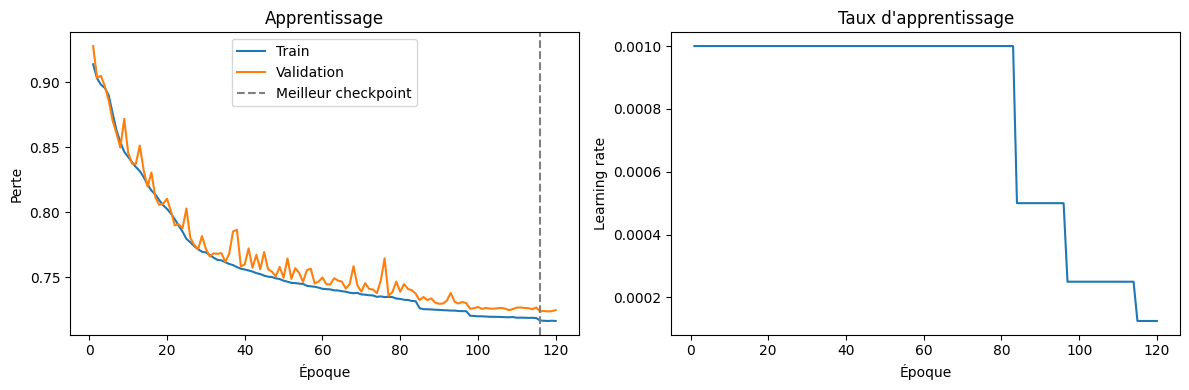

In [36]:
best_epoch = experiment.load_best()

print("Meilleure époque :", best_epoch)

plot_training(
    experiment.history_path,
    output_directory / "figures",
    best_epoch,
)

## 9. Évaluation des performances

Le modèle retenu est évalué sur la **validation**, le **test principal** et la **réserve U**. Les indicateurs sont calculés séparément pour les six paramètres thermiques :

- **MAE** : erreur absolue moyenne, exprimée dans l'unité de la cible ;
- **RMSE** : racine de l'erreur quadratique moyenne, plus sensible aux grandes erreurs ;
- **$R^2$** : coefficient de détermination sur la partition évaluée ;
- **biais** : moyenne des différences entre prédictions et valeurs réelles.

Une référence constante, égale aux **moyennes des cibles du train**, sert de point de comparaison. Les données de test ne sont pas utilisées pour choisir les poids ni modifier les hyperparamètres.

,partition,target,unit,MAE,RMSE,R2,bias
12,test,HLC,W/K,18.6437,23.3779,0.4442,-0.2735
13,test,HLCext,W/K,9.7566,12.1893,0.4911,-0.1323
14,test,HLCmit,W/K,17.8852,22.2635,0.2822,-0.1412
15,test,tau_b,h,7.3590,9.3232,0.1441,0.2297
16,test,tau_n,h,1.3468,1.7128,0.2734,-0.0029
17,test,tau_inf,h,5.5537,7.0776,0.1119,0.1059
24,reserve_u,HLC,W/K,18.6216,23.3374,0.4462,-0.0524
25,reserve_u,HLCext,W/K,9.8016,12.2475,0.4859,-0.0247
26,reserve_u,HLCmit,W/K,17.8700,22.2470,0.2834,-0.0277
27,reserve_u,tau_b,h,7.3912,9.3858,0.1411,0.2296


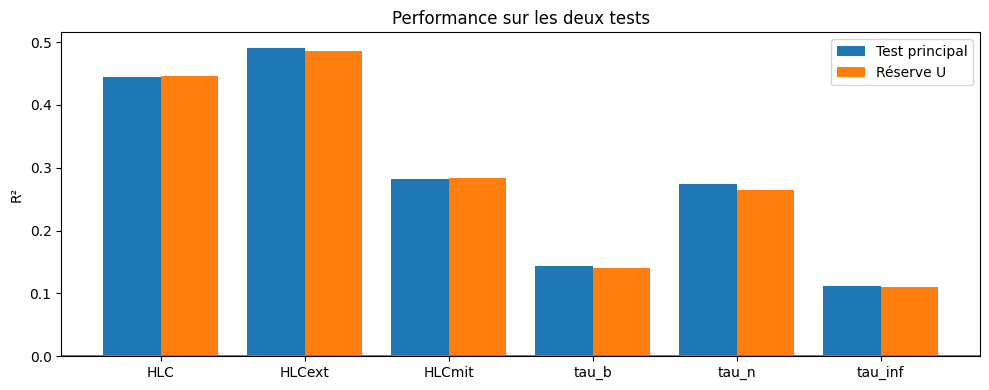

In [37]:
metrics = evaluate_all(experiment)

selected_metrics = metrics[
    (metrics["model"] == MODEL_KIND)
    & (metrics["partition"].isin(["test", "reserve_u"]))
]

display(
    selected_metrics[
        ["partition", "target", "unit", "MAE", "RMSE", "R2", "bias"]
    ].round(4)
)

plot_scores(metrics, MODEL_KIND, output_directory / "figures")

## 10. Analyse des prédictions et des valeurs extrêmes

Les diagrammes de dispersion présentent les valeurs prédites en fonction des valeurs réelles pour le test principal. Leur proximité avec la diagonale permet d'apprécier visuellement la précision et d'éventuels biais.

Une analyse complémentaire examine les constantes de temps $\tau_b$ et $\tau_\infty$ dans les zones extrêmes. Les seuils correspondent aux **5e et 95e percentiles calculés sur le train**, puis les erreurs sont mesurées sur le test principal et la réserve U.

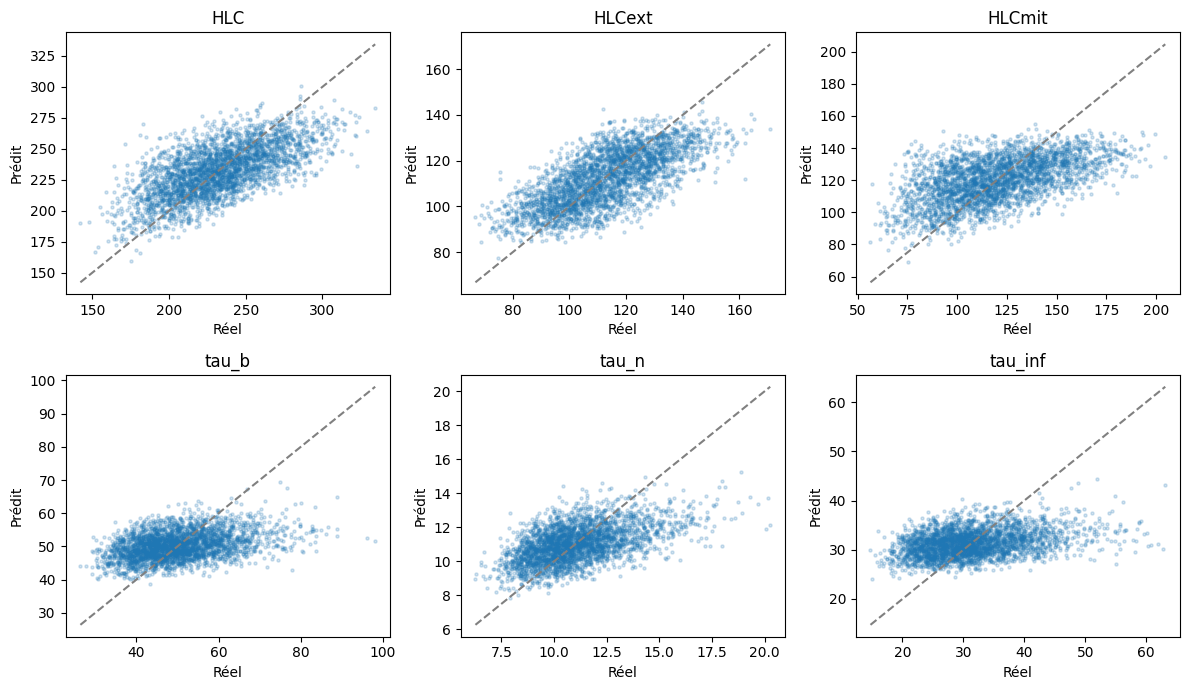

,partition,target,region,n,RMSE,bias
0,test,tau_b,5 % faibles,4447,14.263600,13.833100
1,test,tau_b,5 % élevés,4446,22.425900,-21.368200
2,test,tau_inf,5 % faibles,4475,10.595000,10.334700
3,test,tau_inf,5 % élevés,4399,17.747700,-16.934900
4,reserve_u,tau_b,5 % faibles,5055,14.424700,13.985400
5,reserve_u,tau_b,5 % élevés,5095,22.509399,-21.453600
6,reserve_u,tau_inf,5 % faibles,4987,10.698800,10.431900
7,reserve_u,tau_inf,5 % élevés,5094,17.771299,-16.977501


In [38]:
plot_scatter(
    output_directory / "predictions" / "test.npz",
    output_directory / "figures",
    seed=config.seed,
)

extreme_metrics = extreme_diagnostics(experiment)
display(extreme_metrics.round(4))

## 11. Sauvegarde des résultats

Les modèles entraînés, les configurations, les historiques d'entraînement, les métriques d'évaluation, les prédictions et les figures sont enregistrés afin d'assurer la traçabilité et la reproductibilité des expériences.

L'ensemble des résultats est également regroupé dans une archive ZIP.

In [41]:
results_dir = Path("/kaggle/working/results/fusion_50_50/run_001")

# Vérifier que l'évaluation est terminée
if not (results_dir / "metrics.csv").exists():
    raise FileNotFoundError("Évaluation non terminée : metrics.csv absent.")

# Créer l'archive avec les résultats complets
archive = shutil.make_archive(
    "/kaggle/working/fusion_50_50_coenergy",
    "zip",
    root_dir=results_dir
)

file = Path(archive)

print("Fichier prêt :", file.exists())
print("Taille :", round(file.stat().st_size / 1024**2, 2), "Mo")
print("Nom :", file.name)

Fichier prêt : True
Taille : 12.38 Mo
Nom : fusion_50_50_coenergy.zip



## 12. Analyse et interprétation des résultats

L'architecture de fusion combine deux représentations complémentaires : les caractéristiques temporelles extraites par le CNN-GRU et les caractéristiques statistiques apprises par le MLP. La fonction de perte accorde un poids égal aux coefficients de déperdition et aux constantes de temps.

### Performances prédictives

| Paramètre | R² — Test | R² — Réserve U |
|---|---:|---:|
| HLC | 0.444 | 0.446 |
| HLCext | 0.491 | 0.486 |
| HLCmit | 0.282 | 0.283 |
| τb | 0.144 | 0.141 |
| τn | 0.273 | 0.264 |
| τ∞ | 0.112 | 0.110 |

La fusion 50/50 obtient les meilleures performances des six configurations évaluées sur le test principal, pour chacun des indicateurs thermiques.

L'amélioration par rapport au CNN-GRU individuel reste toutefois modérée. Pour HLCext, le R² passe de 0.481 à 0.491, tandis que pour HLC total, il progresse de 0.440 à 0.444.

Ces gains sont compatibles avec l'hypothèse selon laquelle les caractéristiques statistiques apportent une information complémentaire à la représentation temporelle. Ils ne permettent cependant pas d'isoler précisément cette contribution, puisque la fusion introduit également des paramètres supplémentaires.

Malgré les meilleures performances globales, les constantes de temps τb et τ∞ restent les paramètres les moins bien expliqués. Une sous-dispersion des prédictions demeure visible, ce qui révèle une difficulté persistante à reproduire les valeurs thermiques extrêmes.

Les résultats de la réserve U restent proches de ceux du test principal, sans dégradation importante.

### Conclusion

La fusion CNN-GRU + MLP avec une pondération 50/50 constitue la configuration la plus performante parmi les six expériences réalisées. Elle montre l'intérêt potentiel de combiner des représentations temporelles et statistiques, même si des études d'ablation et des répétitions supplémentaires seraient nécessaires pour confirmer l'origine des gains.
